# 02 - Tyre wear and fuel burn

Before building a model I wanted to see how tyre age and fuel load actually show up in lap times, and whether the effects everyone talks about are visible in this data. The analysis uses 2022 to 2024 only. 2025 is my test season, so I keep it out. The one exception is the Spa 2025 plot below, which is where I first noticed the wet-race problem.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from f1lab.features import drying_races, wet_races

pd.set_option("display.width", 160)
raw = pd.read_parquet("../data/laps.parquet")
clean_all = pd.read_parquet("../data/laps_clean.parquet")
clean_all["race"] = clean_all["season"].astype(str) + "-" + clean_all["round"].astype(str)
len(clean_all), clean_all["race"].nunique()

(81476, 90)

## Not every race is dry

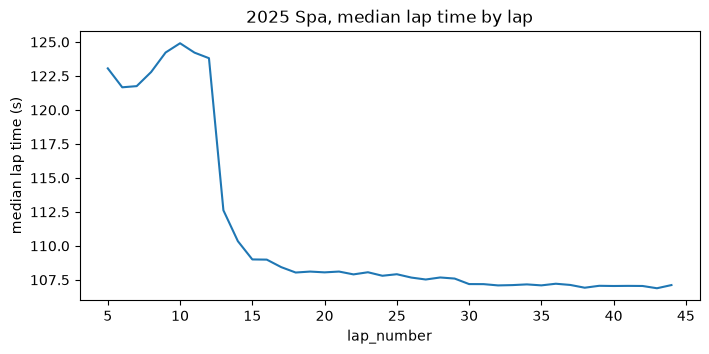

share of laps flagged as rain in the raw data for this race: 0.0


lap_number
(0, 10]     123.0
(10, 20]    108.8
(20, 30]    107.7
(30, 44]    107.1
Name: lap_time_s, dtype: float64

In [2]:
spa = clean_all[clean_all["race"] == "2025-13"]
flag = raw[(raw["season"] == 2025) & (raw["round"] == 13)]["rainfall"].mean()
fig, ax = plt.subplots(figsize=(8, 3.5))
spa.groupby("lap_number")["lap_time_s"].median().plot(ax=ax)
ax.set_ylabel("median lap time (s)")
ax.set_title("2025 Spa, median lap time by lap")
plt.show()
print("share of laps flagged as rain in the raw data for this race:", flag)
spa.groupby(pd.cut(spa["lap_number"], [0, 10, 20, 30, 44]), observed=True)["lap_time_s"].median().round(1)

Looking at Spa 2025, the first ten laps run at about 123 s and the rest at about 107 to 109 s. The track was drying out after a wet start. But the rain flag in the data is 0.0 for the whole race, so I can't rely on that flag to find wet races.

I ended up with two rules in `f1lab/features.py` to drop wet and drying races: one compares early pace with late pace, the other counts how many laps were run on intermediate or wet tyres. Together they remove 12 races from the four seasons.

In [3]:
skip = drying_races(clean_all) | wet_races(raw)
print(len(skip), "races excluded:")
for season, rnd in sorted(skip):
    track = raw[(raw["season"] == season) & (raw["round"] == rnd)]["track"].iloc[0]
    print(f"  {season} round {rnd:2d}  {track}")
c = clean_all[[(s, r) not in skip for s, r in zip(clean_all["season"], clean_all["round"])]].copy()
c = c[c["season"] <= 2024].copy()   # 2025 is the test season, keep it out of the analysis
c["tyre_age"] = c["tyre_age"].astype(float)
c["rel"] = c["lap_time_s"] / c.groupby("race")["lap_time_s"].transform("median")
print(f"\n{len(c)} laps in {c['race'].nunique()} races (2022-2024) left")

12 races excluded:
  2022 round  4  Imola
  2022 round  7  Monte Carlo
  2022 round 17  Singapore
  2022 round 18  Suzuka
  2023 round  7  Monte Carlo
  2023 round 14  Zandvoort
  2024 round  9  Montreal
  2024 round 12  Silverstone
  2024 round 21  Interlagos
  2025 round  1  Melbourne
  2025 round 12  Silverstone
  2025 round 13  Spa-Francorchamps

55553 laps in 59 races (2022-2024) left


That leaves 55,553 laps from 59 races in 2022 to 2024.

## The naive view

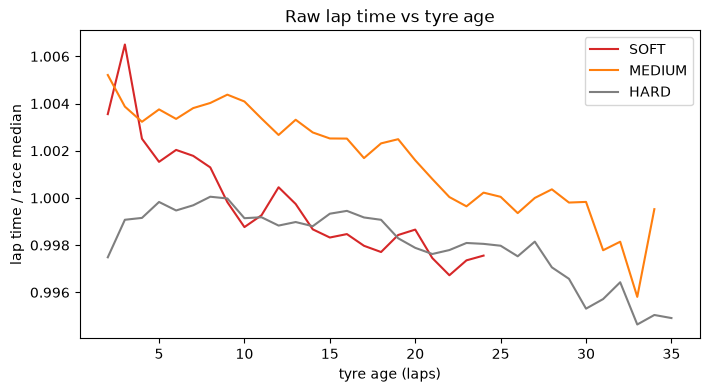

tyre_age,"(0, 5]","(5, 10]","(10, 20]","(20, 35]"
compound,,,,
HARD,0.9990,0.9997,0.9989,0.9970
MEDIUM,1.0039,1.0039,1.0026,0.9998
SOFT,1.0032,1.0008,0.9988,0.9973


In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for comp, colour in (("SOFT", "tab:red"), ("MEDIUM", "tab:orange"), ("HARD", "tab:gray")):
    g = c[(c["compound"] == comp) & (c["tyre_age"] <= 35)]
    s = g.groupby("tyre_age")["rel"].agg(["median", "size"])
    s = s[s["size"] >= 50]
    ax.plot(s.index, s["median"], label=comp, color=colour)
ax.set_xlabel("tyre age (laps)")
ax.set_ylabel("lap time / race median")
ax.legend()
ax.set_title("Raw lap time vs tyre age")
plt.show()
naive = c[c["tyre_age"] <= 35].groupby(["compound", pd.cut(c["tyre_age"], [0, 5, 10, 20, 35])], observed=True)["rel"].median().unstack().round(4)
naive

If I plot lap time against tyre age, the tyres seem to get faster as they age. HARD goes from 0.9990 of race pace in the first five laps to 0.9970 after lap 20, MEDIUM from 1.0039 to 0.9998, SOFT from 1.0032 to 0.9973. That can't be wear. The cars get lighter every lap as fuel burns off, and that gain is bigger than the wear, so it hides it.

## Separating wear from fuel burn

In [5]:
def design(d, with_lap=True):
    X = pd.get_dummies(d[["race", "driver"]], drop_first=True).astype(float)
    if with_lap:
        X["lap_number"] = d["lap_number"]
    for comp in ("SOFT", "MEDIUM", "HARD"):
        X[f"age_{comp}"] = np.where(d["compound"] == comp, d["tyre_age"], 0.0)
        if comp != "HARD":
            X[f"offset_{comp}"] = (d["compound"] == comp).astype(float)
    return X

def fit(d, with_lap):
    X = design(d, with_lap)
    m = LinearRegression().fit(X, d["lap_time_s"])
    return pd.Series(m.coef_, X.columns), m.score(X, d["lap_time_s"])

with_fuel, r2 = fit(c, True)
no_fuel, _ = fit(c, False)
pd.DataFrame(
    {
        "ignoring fuel (s/lap)": no_fuel[["age_SOFT", "age_MEDIUM", "age_HARD"]],
        "with fuel proxy (s/lap)": with_fuel[["age_SOFT", "age_MEDIUM", "age_HARD"]],
    }
).round(4), round(with_fuel["lap_number"], 4), round(r2, 3)

(            ignoring fuel (s/lap)  with fuel proxy (s/lap)
 age_SOFT                  -0.0049                   0.0556
 age_MEDIUM                -0.0164                   0.0379
 age_HARD                  -0.0168                   0.0291,
 np.float64(-0.0508),
 0.988)

To pull the two apart I fit a regression with race and driver fixed effects, which soaks up track, car and driver pace, and added lap number as a stand-in for fuel load.

Without the fuel term every compound shows negative wear, between -0.005 and -0.017 s per lap. With it, wear turns positive and comes out in the order I'd expect: SOFT 0.056, MEDIUM 0.038, HARD 0.029 s per lap, with the fuel term at about -0.051 s per lap. The R-squared of 0.988 is mostly the fixed effects, so I wouldn't read anything into it.

## Does wear change from race to race?

In [6]:
rows = []
for race, g in c[c["compound"].isin(["MEDIUM", "HARD"])].groupby("race"):
    if len(g) < 300 or g["tyre_age"].nunique() < 10:
        continue
    X = pd.get_dummies(g[["driver", "compound"]], drop_first=True).astype(float)
    X["lap"], X["age"] = g["lap_number"], g["tyre_age"]
    coef = LinearRegression().fit(X, g["lap_time_s"]).coef_
    cols = list(X.columns)
    rows.append((race, g["track"].iloc[0], g["season"].iloc[0], g["track_temp"].mean(), coef[cols.index("age")], coef[cols.index("lap")]))
per_race = pd.DataFrame(rows, columns=["race", "track", "season", "temp", "wear", "fuel"])
print(f"races: {len(per_race)} | wear median {per_race['wear'].median():.3f} s/lap, "
      f"IQR {per_race['wear'].quantile(.25):.3f} to {per_race['wear'].quantile(.75):.3f}")
print(f"fuel median {per_race['fuel'].median():.3f} s/lap")
print(f"corr(track temp, wear): pearson {per_race['temp'].corr(per_race['wear']):.2f}, "
      f"spearman {per_race['temp'].corr(per_race['wear'], method='spearman'):.2f}")
per_race.sort_values("wear").iloc[[0, 1, 2, -3, -2, -1]].round(3)

races: 59 | wear median 0.052 s/lap, IQR 0.027 to 0.072
fuel median -0.058 s/lap
corr(track temp, wear): pearson 0.00, spearman 0.03


,race,track,season,temp,wear,fuel
10,2022-20,Mexico City,2022,39.385,-0.069,0.066
51,2024-23,Lusail,2024,22.455,-0.031,-0.066
7,2022-16,Monza,2022,43.433,-0.028,0.014
0,2022-1,Sakhir,2022,27.341,0.148,-0.069
5,2022-14,Spa-Francorchamps,2022,36.330,0.161,-0.078
22,2023-13,Spa-Francorchamps,2023,28.935,0.209,-0.105


Running the same regression one race at a time gives a median wear of 0.052 s per lap across 59 races, with the middle half between 0.027 and 0.072, and a median fuel effect of -0.058. Single races are noisy. Mexico City 2022 comes out at -0.069 and Spa 2023 at 0.209.

Track temperature has no visible relationship with wear (correlation 0.00, or 0.03 by rank). I expected hotter races to wear tyres faster, so that surprised me. This is a rough per-race estimate and a race's average temperature is tangled up with which track it is, so I wouldn't say temperature doesn't matter. It just won't be a strong predictor on its own.

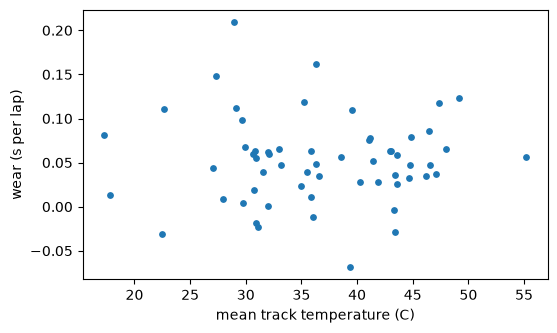

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.scatter(per_race["temp"], per_race["wear"], s=15)
ax.set_xlabel("mean track temperature (C)")
ax.set_ylabel("wear (s per lap)")
plt.show()

## Is wear a track thing?

In [8]:
by_track = per_race.pivot_table(index="track", columns="season", values="wear")
print("correlation of per-track wear between seasons:")
display(by_track.corr().round(2))
avg = per_race.groupby("track")["wear"].mean().sort_values()
avg.round(3).iloc[[0, 1, 2, -3, -2, -1]]

correlation of per-track wear between seasons:


season,2022,2023,2024
season,,,
2022,1.00,0.69,0.64
2023,0.69,1.00,0.30
2024,0.64,0.30,1.00


track
Lusail               0.002
Silverstone          0.002
Mexico City          0.006
Suzuka               0.114
Sakhir               0.119
Spa-Francorchamps    0.144
Name: wear, dtype: float64

Wear looks partly like a property of the track. Per-track wear correlates 0.69 between 2022 and 2023 and 0.64 between 2022 and 2024, but only 0.30 between 2023 and 2024. Lusail, Silverstone and Mexico City show almost no wear (0.002 to 0.006 s per lap) while Spa (0.144), Sakhir (0.119) and Suzuka (0.114) show the most. It's real but unstable, so any track effect in a model should be pulled toward the overall average.

What I take from this for the model:

- Lap number (fuel) has to be in there, or the sign of wear flips.
- Wear should differ by compound, and probably by track, with the track part shrunk toward the average.
- Temperature won't carry much.
- I can't trust the rain flag, so wet races need handling some other way.